# TP2 — Dataset audit companion

## tl;dr

Audit awal 30 Oktober 2026: classification tersedia dan target `artifact_signal` terverifikasi dari skema; regression belum tersedia. Profil lengkap dan hash ada di laporan JSON. Notebook ini mengaudit kualitas data, bukan EDA anggota lain atau training. Status dinamis di bawah mengontrol interpretasi setelah input berubah.

## Context & Methods

Satu baris dianggap satu record; semantik vulnerability dan waktu pembentukan fitur belum dikonfirmasi. Missing dihitung dengan parser CSV pandas default; string sentinel yang tidak dibaca sebagai NA tetap dihitung sebagai kategori. Duplicate row diperiksa dengan dan tanpa ID/target. KS dan total variation bersifat deskriptif; tidak menyatakan penyebab atau signifikansi drift. Test tidak dipakai memilih model.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path.cwd().resolve()
while not (root / "src/utils/paths.py").is_file() and root != root.parent:
    root = root.parent
if not (root / "src/utils/paths.py").is_file():
    raise FileNotFoundError("Open notebook inside the TP2 repository.")
sys.path.insert(0, str(root))
from src.data.audit import audit_task, environment
audits = {task: audit_task(task) for task in ("classification", "regression")}
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": "white", "axes.facecolor": "white"})
print(environment())

{'python': '3.13.5', 'packages': {'pandas': '2.3.3', 'numpy': '2.4.2', 'scipy': '1.18.0', 'matplotlib': '3.10.5', 'nbformat': '5.11.1', 'nbclient': '0.11.0'}}


## Data

File tetap lokal. Target harus satu kolom train-only yang sama dengan kolom prediksi sample (selain record_id). Nilai sample adalah placeholder, bukan label test. Kolom dtype dan kuantil lengkap ada di JSON; tabel di bawah membatasi output agar mudah dibaca.

In [2]:
display(pd.DataFrame([{"task": task, "status": a["status"], "target": a["target"],
                       "target_evidence": a["target_verification"]} for task, a in audits.items()]))
for task, audit in audits.items():
    print(task, "missing:", audit["missing_roles"])
    display(pd.DataFrame([{"split": role, "rows": p["shape"][0], "columns": p["shape"][1],
                           "duplicate_rows": p["exact_duplicate_rows"], "sha256": p["sha256"]}
                          for role, p in audit["files"].items()]))

,task,status,target,target_evidence
0,classification,COMPLETE,artifact_signal,VERIFIED_TRAIN_TEST_SAMPLE_SCHEMA
1,regression,BLOCKED_MISSING_DATA,None,UNVERIFIED


classification missing: []


,split,rows,columns,duplicate_rows,sha256
0,train,50608,19,0,875552a68a3d24b0f3e1966d6ddb5671e6f54305a1c526...
1,test,29421,18,0,4e6c381d582ed24f92d17f620f4f0ad25e2e0def29eb57...
2,sample,29421,2,0,889f97d69659a64945421d841dcf96e5813020606f29b2...


regression missing: ['regression/train', 'regression/test', 'regression/sample']


""


## Results

### Kelengkapan fitur

Bandingkan proporsi missing pada kolom yang sama. Denominator adalah seluruh baris masing-masing split; parser tidak melakukan normalisasi format spread atau telemetry.

,missing_rate_train_pct,missing_rate_test_pct
signal_stream,6.73,3.61
scope_trace,8.36,8.27
org_spread,8.61,8.39
module_spread,8.22,8.50
pattern_code,16.17,8.61
telemetry_flag,11.27,11.11
org_code,5.31,23.27
module_code,7.99,25.14


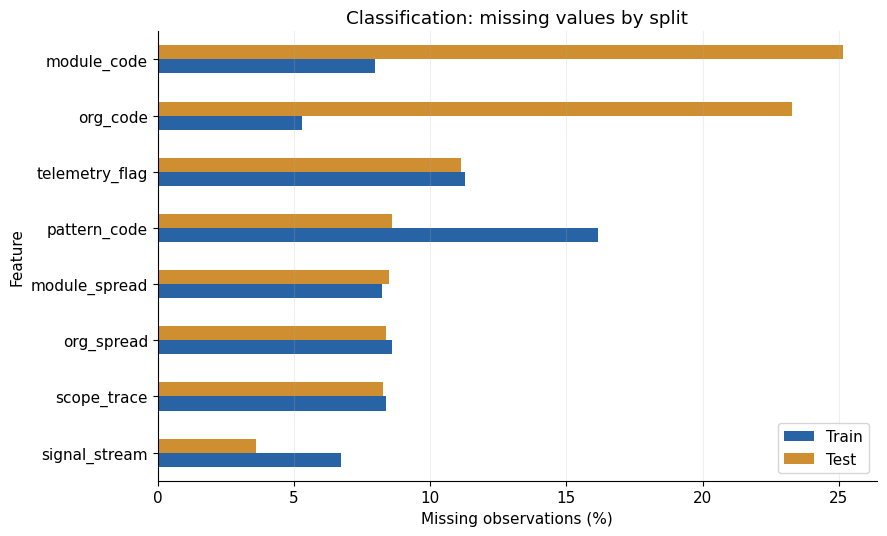

In [3]:
classification = audits["classification"]
comparison = classification.get("comparison", {}).get("columns", {})
missing = pd.DataFrame(comparison).T
if not missing.empty:
    missing = missing[["missing_rate_train", "missing_rate_test"]].astype(float)
    missing = missing.loc[missing.max(axis=1) > 0].sort_values("missing_rate_test")
    display((missing * 100).round(2).rename(columns=lambda s: s + "_pct"))
    if not missing.empty:
        ax = (missing * 100).plot.barh(figsize=(9, 5.5), color=["#2864a5", "#cf8e30"])
        ax.set(title="Classification: missing values by split", xlabel="Missing observations (%)", ylabel="Feature")
        ax.legend(["Train", "Test"])
        ax.grid(axis="x", alpha=.2)
        plt.tight_layout()
        plt.show()

### Target dan skema waktu

Grafik target hanya memakai label train. Cycle adalah kode urut yang arti kalendernya belum diketahui. Cakupan cycle yang terpisah menjadi alasan untuk mempertimbangkan validation berdasarkan urutan, setelah asumsi kronologi dikonfirmasi.

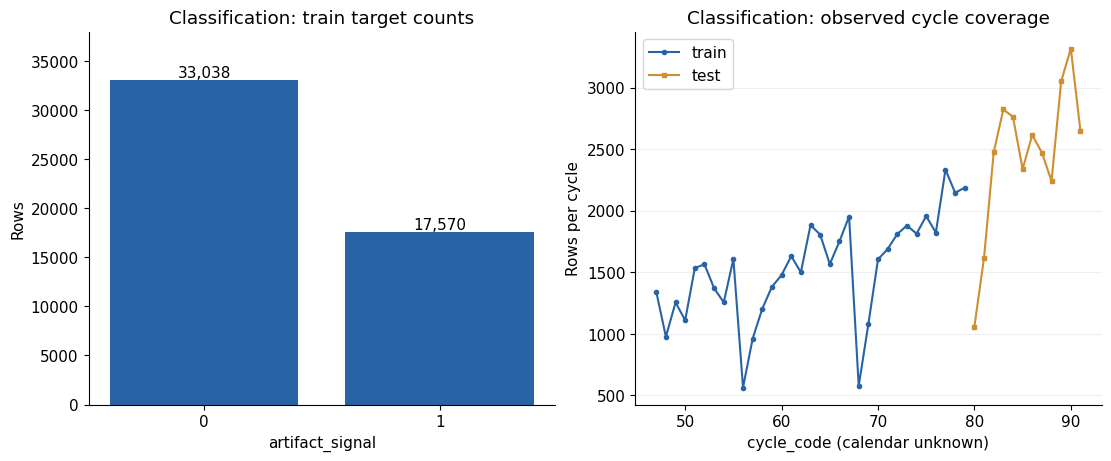

In [4]:
if classification["target"]:
    counts = classification.get("target_summary", {}).get("counts", {})
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
    axes[0].bar(list(counts), list(counts.values()), color="#2864a5")
    axes[0].set(title="Classification: train target counts", xlabel="artifact_signal", ylabel="Rows")
    for i, value in enumerate(counts.values()):
        axes[0].text(i, value, f"{value:,}", ha="center", va="bottom")
    axes[0].margins(y=.15)
    for role, color, marker in [("train", "#2864a5", "o"), ("test", "#cf8e30", "s")]:
        cycle_counts = classification["files"][role].get("cycle_counts", {})
        axes[1].plot([float(x) for x in cycle_counts], list(cycle_counts.values()), label=role, color=color, marker=marker, markersize=3)
    axes[1].set(title="Classification: observed cycle coverage", xlabel="cycle_code (calendar unknown)", ylabel="Rows per cycle")
    axes[1].legend()
    axes[1].grid(axis="y", alpha=.2)
    plt.show()

### Perbedaan distribusi dan pemeriksaan integritas

KS adalah selisih maksimum empirical CDF; bandingkan effect size secara deskriptif. Untuk kolom teks/kode, novelty berarti nilai string penuh yang belum pernah ada, bukan token baru. Distribusi target test tidak dapat dinilai.

In [5]:
if comparison:
    shifts = pd.DataFrame(comparison).T
    display(shifts.reindex(columns=["ks_statistic", "test_unseen_category_count", "test_unseen_category_row_rate_nonmissing"]).sort_values("ks_statistic", ascending=False).round(4))
    integrity = classification["comparison"]
    print({k: v for k, v in integrity.items() if k != "columns"})
    print("Sample alignment:", classification.get("sample_alignment"))
    print("Audit issues:", classification.get("audit_issues", []))

,ks_statistic,test_unseen_category_count,test_unseen_category_row_rate_nonmissing
cycle_code,1.0000,NaN,NaN
scope_pressure,0.2138,NaN,NaN
text_load,0.1551,NaN,NaN
impact_load,0.0943,NaN,NaN
pulse_a,0.0753,NaN,NaN
entry_friction,0.0613,NaN,NaN
pulse_b,0.0237,NaN,NaN
checksum_hint,0.0085,NaN,NaN
org_code,NaN,2047.0,0.2096
module_code,NaN,3744.0,0.3677


{'train_only_columns': ['artifact_signal'], 'test_only_columns': [], 'feature_order_matches': True, 'dtype_mismatches': {}, 'overlapping_ids': 0, 'train_duplicate_feature_rows_excluding_id_target': 0, 'test_duplicate_feature_rows_excluding_id_target': 0, 'shared_distinct_feature_rows': 0}
Sample alignment: {'rows_match_test': True, 'id_order_matches_test': True}
Audit issues: []


## Takeaways

- Pisahkan preprocessing yang dipelajari per fold; tangani kategori baru dan format heterogen tanpa mengubah raw.
- Asal `audit_lane`, `checksum_hint`, serta timing `impact_load`/`entry_friction` perlu bukti domain. Marginal association yang kecil tidak membuktikan fitur aman dari leakage.
- EDA Samuel mengenai `threat_rank` tetap memerlukan data regression resmi. Tidak ada substitusi target atau data lintas-task.
- Dokumen 27 Oktober bersifat historis; hasil aktual sekarang di laporan audit dan output notebook ini.